<a href="https://colab.research.google.com/github/thaibinhhl2006/spam_classification/blob/main/Spam_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Đọc dữ liệu dataset

In [ ]:
from google.colab import files
uploaded = files.upload()


TypeError: 'NoneType' object is not subscriptable

In [ ]:
import pandas as pd
import pandas as pd
dataset = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["Label", "SMS"])
dataset.head()

Chia dataset thành 2 tập training_set và test_set

In [ ]:
# Randomize the dataset
data_randomized = dataset.sample(frac=1, random_state=1)
# Calculate index for split
training_test_index = round(len(data_randomized) * 0.8)
# Split into training and test sets
training_set = data_randomized[:training_test_index].reset_index(drop=True)
test_set = data_randomized[training_test_index:].reset_index(drop=True)
print(training_set.shape)
print(test_set.shape)

(4458, 2)
(1114, 2)


In [ ]:
training_set['Label'].value_counts(normalize=True)

,proportion
Label,
ham,0.86541
spam,0.13459


In [ ]:
test_set['Label'].value_counts(normalize=True)

,proportion
Label,
ham,0.868043
spam,0.131957


Làm sạch dataset

In [ ]:
# Before cleaning
training_set.head(7)

,Label,SMS
0,ham,"Yep, by the pretty sculpture"
1,ham,"Yes, princess. Are you going to make me moan?"
2,ham,Welp apparently he retired
3,ham,Havent.
4,ham,I forgot 2 ask ü all smth.. There's a card on da present lei... How? Ü all want 2 write smth or sign on it?
5,ham,Ok i thk i got it. Then u wan me 2 come now or wat?
6,ham,I want kfc its Tuesday. Only buy 2 meals ONLY 2. No gravy. Only 2 Mark. 2!


In [ ]:
# After cleaning
training_set['SMS'] = training_set['SMS'].str.replace(r'\W', ' ', regex=True)
# Removes punctuation
training_set['SMS'] = training_set['SMS'].str.lower()
training_set.head(7)

,Label,SMS
0,ham,yep by the pretty sculpture
1,ham,yes princess are you going to make me moan
2,ham,welp apparently he retired
3,ham,havent
4,ham,i forgot 2 ask ü all smth there s a card on da present lei how ü all want 2 write smth or sign on it
5,ham,ok i thk i got it then u wan me 2 come now or wat
6,ham,i want kfc its tuesday only buy 2 meals only 2 no gravy only 2 mark 2


In [ ]:
training_set['SMS'] = training_set['SMS'].str.split()
vocabulary = []
for sms in training_set['SMS']:
    for word in sms:
        vocabulary.append(word)
        vocabulary = list(set(vocabulary))

In [ ]:
len(vocabulary)

7783

chuyển dữ liệu về dạng vecto

In [ ]:
word_counts_per_sms = {unique_word: [0] * len(training_set['SMS']) for unique_word in vocabulary}
for index, sms in enumerate(training_set['SMS']):
    for word in sms:
        word_counts_per_sms[word][index] += 1
word_counts = pd.DataFrame(word_counts_per_sms)
word_counts.head()

,ft,staff,begun,people,skillgame,george,ignoring,motivate,lor,entirely,...,calm,recognise,gent,backdoor,christians,2wt,callon,stranger,easier,recycling
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
training_set_clean = pd.concat([training_set, word_counts], axis=1)
training_set_clean.head()

,Label,SMS,ft,staff,begun,people,skillgame,george,ignoring,motivate,...,calm,recognise,gent,backdoor,christians,2wt,callon,stranger,easier,recycling
0,ham,"[yep, by, the, pretty, sculpture]",0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,ham,"[yes, princess, are, you, going, to, make, me, moan]",0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,ham,"[welp, apparently, he, retired]",0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,ham,[havent],0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,ham,"[i, forgot, 2, ask, ü, all, smth, there, s, a, card, on, da, present, lei, how, ü, all, want, 2, write, smth, or, sign, on, it]",0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


1. Mô hình Naive Bayes


Tính các xác suất
| Tên biến       | Ý nghĩa                                      |
| -------------- | -------------------------------------------- |
| `p_spam`       | Xác suất tiên nghiệm tin nhắn là spam        |
| `p_ham`        | Xác suất tiên nghiệm tin nhắn là ham         |
| `n_spam`       | Tổng số từ trong tất cả tin spam             |
| `n_ham`        | Tổng số từ trong tất cả tin ham              |
| `n_vocabulary` | Số lượng từ duy nhất trong toàn tập          |
| `alpha`        | Hệ số làm trơn Laplace (để tránh xác suất 0) |


In [ ]:
# Isolating spam and ham messages first
spam_messages = training_set_clean[training_set_clean['Label'] == 'spam']
ham_messages = training_set_clean[training_set_clean['Label'] == 'ham']
# P(Spam) and P(Ham)
p_spam = len(spam_messages) / len(training_set_clean)
p_ham = len(ham_messages) / len(training_set_clean)
# N_Spam
n_words_per_spam_message = spam_messages['SMS'].apply(len)
n_spam = n_words_per_spam_message.sum()
# N_Ham
n_words_per_ham_message = ham_messages['SMS'].apply(len)
n_ham = n_words_per_ham_message.sum()
# N_Vocabulary
n_vocabulary = len(vocabulary)
# Laplace smoothing
alpha = 1

Tính các xác suất P(word|spam) cho từng từ trong vocabulary

In [ ]:
# Initiate parameters
parameters_spam = {unique_word:0 for unique_word in vocabulary}
parameters_ham = {unique_word:0 for unique_word in vocabulary}
# Calculate parameters
for word in vocabulary:
    n_word_given_spam = spam_messages[word].sum()
    # spam_messages already defined
    p_word_given_spam = (n_word_given_spam + alpha) / (n_spam + alpha*n_vocabulary)
    parameters_spam[word] = p_word_given_spam
    n_word_given_ham = ham_messages[word].sum()
    # ham_messages already defined
    p_word_given_ham = (n_word_given_ham + alpha) / (n_ham + alpha*n_vocabulary)
    parameters_ham[word] = p_word_given_ham

Hàm dự đoán xem tin nhắn là spam hay ham

In [ ]:
import re
def classify(message):
    ''' message: a string '''
    message = re.sub(r'\W', ' ', message)
    message = message.lower().split()
    p_spam_given_message = p_spam
    p_ham_given_message = p_ham
    for word in message:
        if word in parameters_spam:
            p_spam_given_message *= parameters_spam[word]
        if word in parameters_ham:
            p_ham_given_message *= parameters_ham[word]
    print('P(Spam|message):', p_spam_given_message)
    print('P(Ham|message):', p_ham_given_message)
    if p_ham_given_message > p_spam_given_message:
        print('Label: Ham')
        return "Label: Ham"
    elif p_spam_given_message > p_ham_given_message:
        print('Label: Spam')
        return "Label: Spam"
    else: return "Equal proabilities, have a human classify this!"

Kiểm tra bộ lọc

In [ ]:
#test with spam messages
classify("Congratulations! You've won a free ticket to Bahamas! Call 0901234567 now to claim your prize!")
classify("URGENT! Your account has been selected to receive £1000 cash. Reply YES to claim now!")
classify("Win a brand new iPhone 15 today! Click the link to register before midnight!")
classify("You have been selected for a free vacation in Paris. Confirm your details at www.freevacay.com")
classify("Claim your $500 Amazon gift card now! Limited time offer. Visit www.giftpromo.com")


P(Spam|message): 6.276320213395958e-39
P(Ham|message): 1.6990171094822274e-47
Label: Spam
P(Spam|message): 5.974903104342326e-40
P(Ham|message): 2.238325393412275e-50
Label: Spam
P(Spam|message): 1.1546709092657733e-47
P(Ham|message): 1.716708865268323e-49
Label: Spam
P(Spam|message): 9.704234338170606e-42
P(Ham|message): 8.074099431812386e-46
Label: Spam
P(Spam|message): 8.739802239228992e-33
P(Ham|message): 2.548952793448599e-41
Label: Spam


'Label: Spam'

In [ ]:
#test with ham messages
classify("Hey, are we still meeting for dinner tonight?")
classify("Don't forget to pick up some milk on your way home.")
classify("Can you send me the report by tomorrow morning?")
classify("Happy birthday! Hope you have a great day with your family.")
classify("I'm running late, will be there in 10 minutes.")

P(Spam|message): 4.167876145362714e-29
P(Ham|message): 6.321776251068394e-23
Label: Ham
P(Spam|message): 2.030983972768438e-40
P(Ham|message): 6.56500178929187e-34
Label: Ham
P(Spam|message): 2.694122943412935e-29
P(Ham|message): 2.9222071662028356e-24
Label: Ham
P(Spam|message): 7.248105456703031e-35
P(Ham|message): 1.717911944801703e-29
Label: Ham
P(Spam|message): 1.9554948664983945e-33
P(Ham|message): 2.9074115478715596e-28
Label: Ham


'Label: Ham'

Kiểm tra với test_set

In [ ]:
#hàm trả về các nhãn
def classify_test_set(message):
    ''' message: a string '''
    message = re.sub(r'\W', ' ', message)
    message = message.lower().split()
    p_spam_given_message = p_spam
    p_ham_given_message = p_ham
    for word in message:
        if word in parameters_spam:
            p_spam_given_message *= parameters_spam[word]
        if word in parameters_ham:
            p_ham_given_message *= parameters_ham[word]
    if p_ham_given_message > p_spam_given_message: return 'ham'
    elif p_spam_given_message > p_ham_given_message: return 'spam'
    else: return 'needs human classification'

In [ ]:
import gradio as gr
iface = gr.Interface(
    fn=classify,
    inputs=gr.Textbox(lines=2, placeholder="Nhập tin nhắn SMS..."),
    outputs="text",
    title="SMS Spam Classifier",
    description="Nhập tin nhắn SMS và mô hình Naive Bayes sẽ phân loại nó là Spam hay Ham."
)

# Chạy giao diện
iface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7da56a5d5bb5e127be.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
test_set['predicted'] = test_set['SMS'].apply(classify_test_set)
test_set.head(10)

,Label,SMS,predicted
0,ham,Later i guess. I needa do mcat study too.,ham
1,ham,But i haf enuff space got like 4 mb...,ham
2,spam,Had your mobile 10 mths? Update to latest Orange camera/video phones for FREE. Save £s with Free texts/weekend calls. Text YES for a callback orno to opt out,spam
3,ham,All sounds good. Fingers . Makes it difficult to type,ham
4,ham,"All done, all handed in. Don't know if mega shop in asda counts as celebration but thats what i'm doing!",ham
5,ham,But my family not responding for anything. Now am in room not went to home for diwali but no one called me and why not coming. It makes me feel like died.,ham
6,ham,U too...,ham
7,ham,Boo what time u get out? U were supposed to take me shopping today. :(,ham
8,ham,Genius what's up. How your brother. Pls send his number to my skype.,ham
9,ham,I liked the new mobile,ham


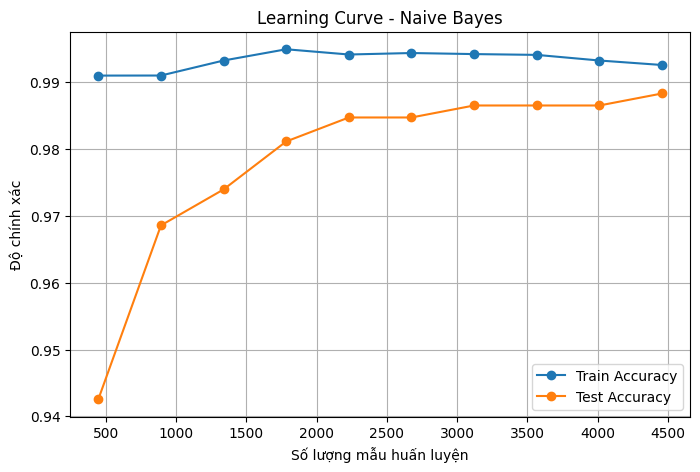

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

train_sizes = np.linspace(0.1, 1.0, 10)
train_scores = []
test_scores = []

for frac in train_sizes:
    n_train = int(len(training_set_clean) * frac)
    train_subset = training_set_clean[:n_train].copy()
    # Tính lại các tham số cho tập nhỏ
    spam_messages = train_subset[train_subset['Label'] == 'spam']
    ham_messages = train_subset[train_subset['Label'] == 'ham']
    p_spam = len(spam_messages) / len(train_subset)
    p_ham = len(ham_messages) / len(train_subset)
    n_spam = spam_messages['SMS'].apply(len).sum()
    n_ham = ham_messages['SMS'].apply(len).sum()
    n_vocabulary = len(vocabulary)
    alpha = 1

    parameters_spam = {unique_word:0 for unique_word in vocabulary}
    parameters_ham = {unique_word:0 for unique_word in vocabulary}
    for word in vocabulary:
        n_word_given_spam = spam_messages[word].sum()
        p_word_given_spam = (n_word_given_spam + alpha) / (n_spam + alpha*n_vocabulary)
        parameters_spam[word] = p_word_given_spam
        n_word_given_ham = ham_messages[word].sum()
        p_word_given_ham = (n_word_given_ham + alpha) / (n_ham + alpha*n_vocabulary)
        parameters_ham[word] = p_word_given_ham

    # Hàm dự đoán cho learning curve
    def classify_lc(message):
        import re
        message = re.sub(r'\W', ' ', message)
        message = message.lower().split()
        p_spam_given_message = p_spam
        p_ham_given_message = p_ham
        for word in message:
            if word in parameters_spam:
                p_spam_given_message *= parameters_spam[word]
            if word in parameters_ham:
                p_ham_given_message *= parameters_ham[word]
        return 'spam' if p_spam_given_message > p_ham_given_message else 'ham'

    # Độ chính xác trên tập train
    train_pred = train_subset['SMS'].apply(lambda sms: classify_lc(' '.join(sms) if isinstance(sms, list) else sms))
    train_acc = (train_pred == train_subset['Label']).mean()
    train_scores.append(train_acc)

    # Độ chính xác trên tập test
    test_pred = test_set['SMS'].apply(lambda sms: classify_lc(sms))
    test_acc = (test_pred == test_set['Label']).mean()
    test_scores.append(test_acc)

plt.figure(figsize=(8,5))
plt.plot(train_sizes * len(training_set_clean), train_scores, 'o-', label='Train Accuracy')
plt.plot(train_sizes * len(training_set_clean), test_scores, 'o-', label='Test Accuracy')
plt.xlabel('Số lượng mẫu huấn luyện')
plt.ylabel('Độ chính xác')
plt.title('Learning Curve - Naive Bayes')
plt.legend()
plt.grid(True)
plt.show()

Kiểm tra độ chính xác và các chỉ số khác

In [ ]:
TP = FP = TN = FN = 0

for row in test_set.iterrows():
    row = row[1]
    if row['Label'] == 'spam' and row['predicted'] == 'spam':
        TP += 1
    elif row['Label'] == 'ham' and row['predicted'] == 'ham':
        TN += 1
    elif row['Label'] == 'ham' and row['predicted'] == 'spam':
        FP += 1
    elif row['Label'] == 'spam' and row['predicted'] == 'ham':
        FN += 1
total = TP + FP + TN + FN
naiveBayesAccuracy = (TP + TN) / total

naiveBayesPrecision = 0
if (TP + FP) > 0:
    naiveBayesPrecision = TP / (TP + FP)

naiveBayesRecall = 0
if (TP + FN) > 0:
    naiveBayesRecall = TP / (TP + FN)

naiveBayesf1 = 2 * naiveBayesPrecision * naiveBayesRecall / (naiveBayesPrecision + naiveBayesRecall)

print("Accuracy: {:.2f}%".format(naiveBayesAccuracy * 100))
print("Precision: {:.2f}%".format(naiveBayesPrecision * 100))
print("Recall: {:.2f}%".format(naiveBayesRecall * 100))
print("F1 score: {:.2f}%".format(naiveBayesf1 * 100))




Accuracy: 98.83%
Precision: 96.53%
Recall: 94.56%
F1 score: 95.53%


Mô hình Logistic Regression

Chuẩn bị dữ liệu train

In [ ]:
X_train = word_counts.values
y_train = training_set['Label'].map({'ham': 0, 'spam': 1}).values

Chuẩn bị dữ liệu test

In [ ]:
sms_split = test_set['SMS'].str.replace(r'\W', ' ', regex=True).str.lower().str.split()

test_word_counts = {word: [0] * len(test_set) for word in vocabulary}

for index, sms in enumerate(sms_split):
    for word in sms:
        if word in test_word_counts:
            test_word_counts[word][index] += 1

X_test = pd.DataFrame(test_word_counts).values
y_test = test_set['Label'].map({'ham': 0, 'spam': 1}).values

Cài đặt Logistic Regression bằng thuật toán

In [ ]:
import numpy as np

def sigmoid(z):
    z = np.clip(z, -50, 50)
    return 1 / (1 + np.exp(-z))

def train_logistic_regression(X, y, lr=0.2, epochs=500):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0

    for _ in range(epochs):
        z = X @ w + b
        p = sigmoid(z)

        error = p - y
        w -= lr * (X.T @ error) / n
        b -= lr * error.mean()

    return w, b

def predict_logistic_regression(X, w, b):
    return (sigmoid(X @ w + b) >= 0.5).astype(int)


Huấn luyện và đánh giá mô hình

In [ ]:
X_train_np = np.array(X_train, dtype=float)
X_test_np  = np.array(X_test, dtype=float)
y_train_np = np.array(y_train, dtype=float)
y_test_np  = np.array(y_test, dtype=float)

w, b = train_logistic_regression(X_train_np, y_train_np)

y_pred = predict_logistic_regression(X_test_np, w, b)

logicAccuracy = (y_pred == y_test_np).mean()
print(f"Độ chính xác (Logistic Regression - thuật toán): {logicAccuracy*100:.2f}%")

# Đã có: y_pred (dự đoán), y_test_np (thực tế)

# Tính Precision, Recall, F1 cho bài toán nhị phân (spam = 1, ham = 0)
TP = FP = TN = FN = 0
for i in range(len(y_test_np)):
    if y_test_np[i] == 1 and y_pred[i] == 1:
        TP += 1
    elif y_test_np[i] == 0 and y_pred[i] == 0:
        TN += 1
    elif y_test_np[i] == 0 and y_pred[i] == 1:
        FP += 1
    elif y_test_np[i] == 1 and y_pred[i] == 0:
        FN += 1

logicPrecision = TP / (TP + FP) if (TP + FP) > 0 else 0
logicRecall = TP / (TP + FN) if (TP + FN) > 0 else 0
logicF1 = 2 * logicPrecision * logicRecall / (logicPrecision + logicRecall) if (logicPrecision + logicRecall) > 0 else 0

print(f"Precision: {logicPrecision*100:.2f}%")
print(f"Recall: {logicRecall*100:.2f}%")
print(f"F1 score: {logicF1*100:.2f}%")


P(Spam|message): 2.3434379840481005e-05
P(Ham|message): 0.0004924667552338176
Label: Ham
Độ chính xác (Logistic Regression - thuật toán): 97.85%
Precision: 97.67%
Recall: 85.71%
F1 score: 91.30%


Demo

In [ ]:
import gradio as gr
import re

def classify_logistic(message):
    """Phân loại tin nhắn bằng Logistic Regression"""
    # Tiền xử lý tin nhắn
    message_clean = re.sub(r'\W', ' ', message).lower().split()

    # Tạo vector đặc trưng cho tin nhắn
    message_vector = np.zeros(len(vocabulary))
    for word in message_clean:
        if word in vocabulary:
            idx = vocabulary.index(word)
            message_vector[idx] += 1

    # Dự đoán
    prob = sigmoid(message_vector @ w + b)
    prediction = "spam" if prob >= 0.5 else "ham"

    result = f"P(Spam): {prob:.4f}\n"
    result += f"P(Ham): {1-prob:.4f}\n"
    result += f"Label: {prediction.upper()}"
    return result

iface_logistic = gr.Interface(
    fn=classify_logistic,
    inputs=gr.Textbox(lines=2, placeholder="Nhập tin nhắn SMS..."),
    outputs="text",
    title="SMS Spam Classifier - Logistic Regression",
    description="Nhập tin nhắn SMS và mô hình Logistic Regression sẽ phân loại nó là Spam hay Ham."
)

iface_logistic.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://422eec6495ffb0c861.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


3. Mô hình SVM

Chuẩn bị dữ liệu test

In [ ]:
sms_split = test_set['SMS'].str.replace(r'\W', ' ', regex=True).str.lower().str.split()

test_word_counts = {word: [0] * len(test_set) for word in vocabulary}

for index, sms in enumerate(sms_split):
    for word in sms:
        if word in test_word_counts:
            test_word_counts[word][index] += 1

X_test = pd.DataFrame(test_word_counts).values
y_test = test_set['Label'].map({'ham': 0, 'spam': 1}).values

Tạo vector số cho bộ test

In [ ]:
X_train = training_set_clean.drop(columns=['Label', 'SMS']).values
y_train = training_set_clean['Label'].map({'ham': 0, 'spam': 1}).values

Thêm thư viện để huấn luyện

In [ ]:
from sklearn.svm import LinearSVC

clf = LinearSVC(C=0.1)
clf.fit(X_train, y_train)


LinearSVC(C=0.1)

Kiểm tra kết quá

In [ ]:
y_pred = clf.predict(X_test)
test_set['predicted'] = y_pred
test_set['predicted_label'] = test_set['predicted'].map({0: 'ham', 1: 'spam'})
test_set[['SMS', 'Label', 'predicted_label']].head(10)

,SMS,Label,predicted_label
0,Later i guess. I needa do mcat study too.,ham,ham
1,But i haf enuff space got like 4 mb...,ham,ham
2,Had your mobile 10 mths? Update to latest Orange camera/video phones for FREE. Save £s with Free texts/weekend calls. Text YES for a callback orno to opt out,spam,spam
3,All sounds good. Fingers . Makes it difficult to type,ham,ham
4,"All done, all handed in. Don't know if mega shop in asda counts as celebration but thats what i'm doing!",ham,ham
5,But my family not responding for anything. Now am in room not went to home for diwali but no one called me and why not coming. It makes me feel like died.,ham,ham
6,U too...,ham,ham
7,Boo what time u get out? U were supposed to take me shopping today. :(,ham,ham
8,Genius what's up. How your brother. Pls send his number to my skype.,ham,ham
9,I liked the new mobile,ham,ham


Các thư bị đoán sai

In [ ]:
wrong = test_set[test_set['Label'] != test_set['predicted_label']]
wrong[['SMS', 'Label', 'predicted_label']].head(10)


,SMS,Label,predicted_label
114,Not heard from U4 a while. Call me now am here all night with just my knickers on. Make me beg for it like U did last time 01223585236 XX Luv Nikiyu4.net,spam,ham
207,Miss call miss call khelate kintu opponenter miss call dhorte lage. Thats d rule. One with great phone receiving quality wins.,ham,spam
218,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru email. Never share your password with anybody.",ham,spam
363,Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123,spam,ham
504,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50",spam,ham
512,Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit request after expiry. Reply THEMOB HELP 4 more info,spam,ham
546,"Hi babe its Chloe, how r u? I was smashed on saturday night, it was great! How was your weekend? U been missing me? SP visionsms.com Text stop to stop 150p/text",spam,ham
604,88066 FROM 88066 LOST 3POUND HELP,spam,ham
673,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner,spam,ham
876,RCT' THNQ Adrian for U text. Rgds Vatian,spam,ham


Các thư bị nhầm là span

In [ ]:
false_spam = test_set[
    (test_set['Label'] == 'ham') &
    (test_set['predicted_label'] == 'spam')
]

false_spam[['SMS', 'Label', 'predicted_label']].head(10)


,SMS,Label,predicted_label
207,Miss call miss call khelate kintu opponenter miss call dhorte lage. Thats d rule. One with great phone receiving quality wins.,ham,spam
218,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru email. Never share your password with anybody.",ham,spam
1004,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru email. Never share your password with anybody.",ham,spam
1073,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &lt;#&gt;,ham,spam


Độ chính xác

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
svmAccuracy = accuracy_score(y_test, y_pred)
svmPrecision = precision_score(y_test, y_pred)
svmRecall = recall_score(y_test, y_pred)
svmF1 = f1_score(y_test, y_pred)
print("Accuracy:", svmAccuracy*100, "%")
print("Precision:", svmPrecision*100, "%")
print("Recall:", svmRecall*100, "%")
print("F1 score:", svmF1*100, "%")

Accuracy: 98.56373429084381 %
Precision: 97.12230215827337 %
Recall: 91.83673469387756 %
F1 score: 94.4055944055944 %


Demo

In [ ]:
import gradio as gr
import re

def classify_svm(message):
    """Phân loại tin nhắn bằng SVM"""
    # Tiền xử lý tin nhắn
    message_clean = re.sub(r'\W', ' ', message).lower().split()

    # Tạo vector đặc trưng cho tin nhắn
    message_vector = np.zeros(len(vocabulary))
    for word in message_clean:
        if word in vocabulary:
            idx = vocabulary.index(word)
            message_vector[idx] += 1

    # Dự đoán
    prediction = clf.predict([message_vector])[0]
    decision_score = clf.decision_function([message_vector])[0]

    label = "SPAM" if prediction == 1 else "HAM"

    result = f"Decision Score: {decision_score:.4f}\n"
    result += f"(Score > 0 → Spam, Score < 0 → Ham)\n"
    result += f"Label: {label}"
    return result

iface_svm = gr.Interface(
    fn=classify_svm,
    inputs=gr.Textbox(lines=2, placeholder="Nhập tin nhắn SMS..."),
    outputs="text",
    title="SMS Spam Classifier - SVM",
    description="Nhập tin nhắn SMS và mô hình SVM sẽ phân loại nó là Spam hay Ham."
)

iface_svm.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f2c71d6664606e66d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


So sánh các mô hình

Đầu tiên ta vẽ bảng để có cái nhìn tổng quan

In [ ]:
import pandas as pd

# Thay các giá trị dưới đây bằng kết quả thực tế bạn đã tính được
results = {
    "Model": ["Naive Bayes", "Logistic Regression", "SVM"],
    "Accuracy (%)": [naiveBayesAccuracy*100, logicAccuracy*100, svmAccuracy*100],
    "Precision (%)": [naiveBayesPrecision*100, logicPrecision*100, svmPrecision*100],
    "Recall (%)": [naiveBayesRecall*100, logicRecall*100, svmRecall*100],
    "F1 (%)": [naiveBayesf1*100, logicF1*100, svmF1*100]
}

df = pd.DataFrame(results)
df = df.round(2)  # Làm tròn 2 chữ số thập phân
display(df)

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
0,Naive Bayes,98.83,96.53,94.56,95.53
1,Logistic Regression,97.85,97.67,85.71,91.30
2,SVM,98.56,97.12,91.84,94.41


Ta vẽ biểu đồ cột so sánh 3 modal với theo precision - recall - F1

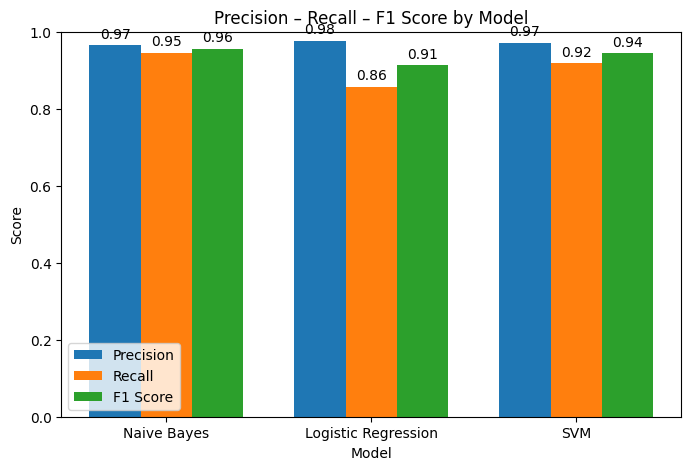

In [ ]:
# ...existing code...

import matplotlib.pyplot as plt
import numpy as np

# Các giá trị đã tính được ở các cell trước
models = ['Naive Bayes', 'Logistic Regression', 'SVM']
precisions = [naiveBayesPrecision, logicPrecision, svmPrecision]
recalls = [naiveBayesRecall, logicRecall, svmRecall]
f1s = [naiveBayesf1, logicF1, svmF1]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(8,5))
rects1 = ax.bar(x - width, precisions, width, label='Precision')
rects2 = ax.bar(x, recalls, width, label='Recall')
rects3 = ax.bar(x + width, f1s, width, label='F1 Score')

ax.set_ylabel('Score')
ax.set_xlabel('Model')
ax.set_title('Precision – Recall – F1 Score by Model')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.legend()

for rect in rects1 + rects2 + rects3:
    height = rect.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom')

plt.show()

Radar chart

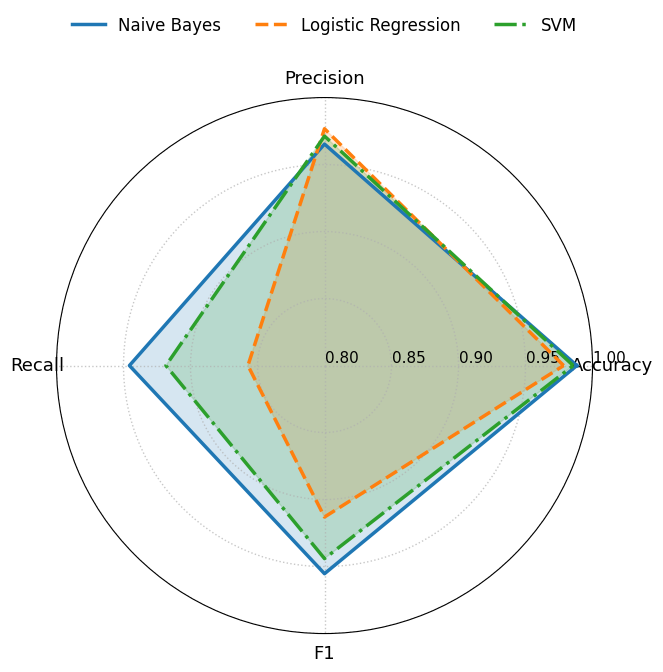

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

labels = ['Accuracy', 'Precision', 'Recall', 'F1']
nb_scores = [naiveBayesAccuracy, naiveBayesPrecision, naiveBayesRecall, naiveBayesf1]
lr_scores = [logicAccuracy, logicPrecision, logicRecall, logicF1]
svm_scores = [svmAccuracy, svmPrecision, svmRecall, svmF1]

scores = [nb_scores, lr_scores, svm_scores]
model_names = ['Naive Bayes', 'Logistic Regression', 'SVM']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
linestyles = ['solid', 'dashed', 'dashdot']

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
plt.subplots_adjust(top=0.78)

for i, score in enumerate(scores):
    data = score + score[:1]
    ax.plot(angles, data, label=model_names[i], linewidth=2.5, color=colors[i], linestyle=linestyles[i])
    ax.fill(angles, data, color=colors[i], alpha=0.18)

ax.set_thetagrids(np.degrees(angles[:-1]), labels, fontsize=13)
ax.set_ylim(0.8, 1)
ax.set_yticks([0.8, 0.85, 0.9, 0.95, 1.0])
ax.set_yticklabels(['0.80', '0.85', '0.90', '0.95', '1.00'], fontsize=11)
ax.grid(True, linestyle=':', linewidth=1, alpha=0.7)
ax.set_rlabel_position(0)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.18), ncol=3, fontsize=12, frameon=False)
plt.show()